# Calling structures from single cells

One single-cell Hi-C map holds 10⁴–10⁶ contacts, too few for the callers of bulk Hi-C.  This tutorial goes
through the four routes U-Chrom offers instead, on real data, each checked against an independent reference:

1. **loops across cells** without pooling them — SnapHiC: every cell's map imputed by a random walk with
   restart, every candidate pixel tested against its local background over the cells;
2. **domain boundaries of single cells** — the insulation of each cell's imputed map, and their consensus;
3. **compartment values of every cell** — scA/B, the mean CpG frequency of each bin's contact partners;
4. **the tracing callers on reconstructed 3-D structures** — a reconstruction is a `ChromData` with
   coordinates.

- **Data**: Nagano et al. 2017 diploid mES cells (`ds.load("nagano2017_dip_serum")`: 1,175 cells, 10 kb
  maps per cell; the 742 deepest, as SnapHiC used), with SnapHiC's published loops and reference lists
  (`yu2021_snaphic`) and the bulk Hi-C of Bonev et al. 2017 (`bonev2017_mesc_4dn`); Tan et al. 2018 Dip-C
  GM12878 structures (`ds.load("tan2018_gm12878")`) against Rao et al. 2014 GM12878 Hi-C.
- **Runtime**: about 20 min on 32 cores with the native kernels (`uchrom-maps`); this notebook was executed
  on a cluster node (Sherlock).

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import uchrom as uc
import uchrom.datasets as ds
from uchrom.fea import add_sequence_features, contact_matrix, rebin_map
from uchrom.io import read_juicer_loops
from uchrom.strc.comp import CompartmentCallerParams, compare_compartments
from uchrom.strc.loop import match_loops
from uchrom.strc.tad import compare_boundaries

plt.rcParams["figure.dpi"] = 90
OUT = Path("_out") / "sc_structures"; OUT.mkdir(parents=True, exist_ok=True)   # outputs: tutorials/_out/
THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count()))
T0 = time.time()

cd = ds.load("nagano2017_dip_serum", backed=True)        # built once from the original files (fetch + loader)
top = cd.cells.index[cd.cells["snaphic_top742"]]        # SnapHiC's cells: the 742 with the most contacts
print(cd)
cd.cells.loc[top].groupby("group", observed=True).agg(cells=("n_contacts", "size"),
                                                      median_contacts=("n_contacts", "median"))

ChromData (backed: nagano2017_dip_serum.chromdata.zarr): n_spots=0, n_traces=0, n_cells=1175, n_bins=0
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['batch_name', 'cond', 'group', 'passed_qc', 'total_contacts', 'f_trans', 'repli_score', 'n_fend_pairs', 'n_unmapped', 'n_contacts', 'n_cis', 'n_trans', 'frac_cis', 'snaphic_top742', 'cell_type'] (1175 cells)
  uns:     ['genome_assembly', 'source', 'haplotypes', 'linked_scool', 'dataset']


,cells,median_contacts
group,,
G1,128,293240.0
early-S,302,310313.5
late-S/G2,265,317862.0
post-M,4,354351.0
pre-M,14,360648.0


## 1. Loops across cells: SnapHiC

`uc.tl.call_loops(cd, method="snaphic")` imputes each cell's map (whole chromosomes, 10 kb), turns it into
per-diagonal z-scores and tests every pixel against its local background over the cells (paired t-test, FDR
per distance, SnapHiC's filters and clustering).  It excludes SnapHiC's low-mappability bins.  Two
chromosomes here, to keep the notebook short (genome-wide: ~1.5 h on 32 cores).

In [2]:
CHROMS = ["chr18", "chr19"]
exclude = ds.fetch("snaphic_filter_regions", verbose=False) / "mm10_filter_regions.txt"
t = time.time()
loops = uc.tl.call_loops(cd, method="snaphic", cells=top, chrom=CHROMS, exclude=exclude, n_threads=THREADS)
print(f"{len(loops):,} loops on {', '.join(CHROMS)} from {len(top)} cells in {time.time() - t:.0f} s")
loops.head(3)

1,353 loops on chr18, chr19 from 742 cells in 229 s


,chrom1,start1,end1,chrom2,start2,end2,score,outlier_count,pvalue,tstat,fdr_dist,case_avg,control_avg,circle,donut,horizontal,vertical,lower_left,cluster_size,neg_log10_fdr
0,chr18,3260000,3270000,chr18,4000000,4010000,3.173759,122,2.968312e-05,4.202004,0.000670,0.908661,0.515784,74.906250,75.317460,87.666667,87.500000,66.428571,108,556.775533
1,chr18,3260000,3270000,chr18,4150000,4160000,2.501121,128,1.982755e-04,3.739928,0.003154,1.066955,0.665968,87.552083,87.460317,95.166667,103.833333,81.000000,108,556.775533
2,chr18,3270000,3280000,chr18,3420000,3430000,5.676689,123,1.636099e-07,5.287178,0.000002,0.701035,0.329022,73.302083,68.047619,86.666667,86.833333,81.380952,108,556.775533


The paper's measures (Yu et al. 2021): a call overlaps a loop when both anchors are within 20 kb;
**precision** against the combined mESC reference (HiCCUPS on bulk Hi-C + MAPS on H3K4me3 PLAC-seq,
cohesin and H3K27ac HiChIP), **recall** of the bulk HiCCUPS loops, both in 100 kb – 1 Mb.  The paper's own
calls from the same 742 cells are the yardstick.

In [3]:
src = ds.fetch("yu2021_snaphic", verbose=False)         # the paper's source data (two workbooks)
refs = src / "41592_2021_1231_MOESM6_ESM.xlsx"
def in_range(t):                                     # loops of CHROMS, anchors 100 kb - 1 Mb apart
    sep = t["start2"] - t["start1"]
    return t[t["chrom1"].isin(CHROMS) & (sep >= 100_000) & (sep <= 1_000_000)].reset_index(drop=True)

bulk_hiccups = in_range(read_juicer_loops(refs, sheet="Bulk_HiC_filter"))
reference = in_range(pd.concat([read_juicer_loops(refs, sheet=f"{s}_filter") for s in
                                ("Bulk_HiC", "H3K4me3_PLACseq", "cohesin_HiChIP", "H3K27ac_HiChIP")])
                     .drop_duplicates(["chrom1", "start1", "start2"]))
paper = in_range(read_juicer_loops(src / "41592_2021_1231_MOESM4_ESM.xlsx", sheet="Permu0_742"))

def scores(calls):
    calls = in_range(calls)
    return {"loops": len(calls), "precision": match_loops(calls, reference, tol=20_000).mean(),
            "recall": match_loops(bulk_hiccups, calls, tol=20_000).mean()}

rows = {"U-Chrom SnapHiC": scores(loops), "the paper's SnapHiC": scores(paper)}
print(f"{len(paper)} paper loops; {match_loops(paper, loops, tol=20_000).mean():.0%} of them within 20 kb of ours")
pd.DataFrame(rows).T.round(2)

1090 paper loops; 76% of them within 20 kb of ours


,loops,precision,recall
U-Chrom SnapHiC,1292.0,0.62,0.61
the paper's SnapHiC,1090.0,0.67,0.60


What pooling the same cells gives instead: their maps summed into one pseudo-bulk map, then HiCCUPS — and
the pileup of SnapHiC's loops on that map (APA, with the loops shifted by ±0.5 / ±1 Mb as the control).

In [4]:
t = time.time()
uc.tl.pseudobulk(cd, pd.Series("top742", index=top), trans=False, key_prefix="pooled", out_dir=OUT)
pooled = uc.tl.call_loops(cd, method="hiccups", contacts="pooled.top742", chrom=CHROMS, key_added="loops.pooled")
apa = uc.tl.pileup(cd, loops, contacts="pooled.top742", shifts=(-1_000_000, -500_000, 500_000, 1_000_000),
                   key_added=None)
rows["HiCCUPS on the pooled map"] = scores(pooled)
print(f"pooled map + HiCCUPS in {time.time() - t:.0f} s; APA of the SnapHiC loops on it {apa['apa']:.2f} "
      f"(shifted {apa['control']:.2f})")
pd.DataFrame(rows).T.round(2)

pooled map + HiCCUPS in 2 s; APA of the SnapHiC loops on it 1.93 (shifted 0.98)


,loops,precision,recall
U-Chrom SnapHiC,1292.0,0.62,0.61
the paper's SnapHiC,1090.0,0.67,0.60
HiCCUPS on the pooled map,34.0,0.97,0.06


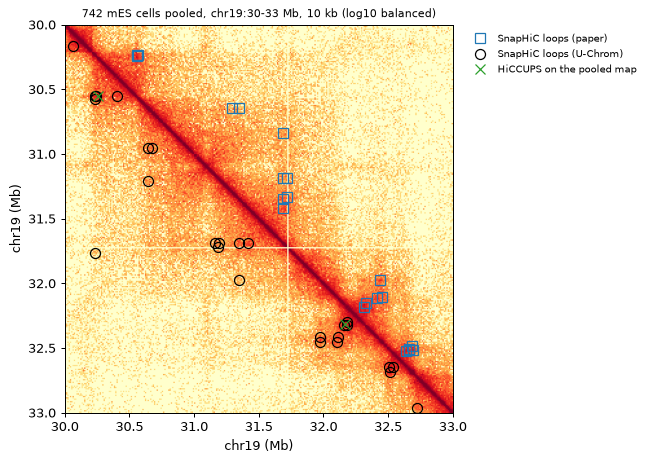

In [5]:
R0, R1, RES = 30_000_000, 33_000_000, 10_000
bins, M = contact_matrix(cd, "pooled.top742", chrom="chr19")
lo, hi = R0 // RES, R1 // RES
x0, x1 = R0 / 1e6, R1 / 1e6
def mids(t):
    t = t[(t["chrom1"] == "chr19") & (t["start1"] >= R0) & (t["end2"] <= R1)]
    return (t["start1"] + t["end1"]) / 2e6, (t["start2"] + t["end2"]) / 2e6

fig, ax = plt.subplots(figsize=(6, 5.6))
ax.imshow(np.log10(M[lo:hi, lo:hi] + 1e-6), cmap="YlOrRd", vmin=-3.6, vmax=-1.2, extent=[x0, x1, x1, x0])
a, b = mids(paper);  ax.plot(b, a, "s", mfc="none", mec="C0", ms=8, label="SnapHiC loops (paper)")
a, b = mids(loops);  ax.plot(a, b, "o", mfc="none", mec="k", ms=8, label="SnapHiC loops (U-Chrom)")
a, b = mids(pooled); ax.plot(a, b, "x", color="C2", ms=8, label="HiCCUPS on the pooled map")
ax.set_xlim(x0, x1); ax.set_ylim(x1, x0); ax.set_xlabel("chr19 (Mb)"); ax.set_ylabel("chr19 (Mb)")
ax.set_title(f"742 mES cells pooled, chr19:{x0:.0f}-{x1:.0f} Mb, 10 kb (log10 balanced)", fontsize=9)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
plt.show()

## 2. Domain boundaries of single cells

`uc.tl.single_cell_boundaries` computes the insulation score of each cell's imputed map, each cell's
boundaries, and consensus boundaries from the cells' mean insulation.  The reference is the insulation of bulk
Hi-C of the same cell type (Bonev et al. 2017, 10 kb, 100 kb window).

In [6]:
t = time.time()
sc_bounds = uc.tl.single_cell_boundaries(cd, cells=top, chrom="chr19", per_cell=True, n_threads=THREADS)
print(f"chr19, {len(top)} cells in {time.time() - t:.0f} s: {int(sc_bounds['consensus'].sum())} consensus boundaries")

cd.link_cool(ds.path("bonev2017_mesc_4dn"), key="bonev")              # bulk mESC Hi-C (4DN mcool)
uc.tl.call_tads(cd, method="insulation", contacts="bonev", resolution=10_000, chrom="chr19", key_added="tads.bonev")
consensus = pd.DataFrame(cd.intervals["tads.single_cell.domains"])
near = compare_boundaries(cd, consensus, "tads.bonev", tol=2, contacts="bonev", resolution=10_000)
found = compare_boundaries(cd, "tads.bonev", consensus, tol=2, contacts="bonev", resolution=10_000)
print(f"consensus boundaries near a bulk boundary (±2 bins): {near['fraction_near']:.2f} (chance {near['chance']:.2f}); "
      f"bulk boundaries recovered: {found['fraction_near']:.2f} (chance {found['chance']:.2f})")
bulk_ins = cd.results["tads.bonev.score"]
both = sc_bounds.merge(bulk_ins[["chrom", "start", "log2_insulation_score_100000"]], on=["chrom", "start"])
print("mean single-cell insulation vs bulk insulation, Spearman "
      f"{both['insulation'].corr(both['log2_insulation_score_100000'], method='spearman'):.2f}")

chr19, 742 cells in 45 s: 179 consensus boundaries


consensus boundaries near a bulk boundary (±2 bins): 0.73 (chance 0.14); bulk boundaries recovered: 0.76 (chance 0.15)
mean single-cell insulation vs bulk insulation, Spearman 0.65


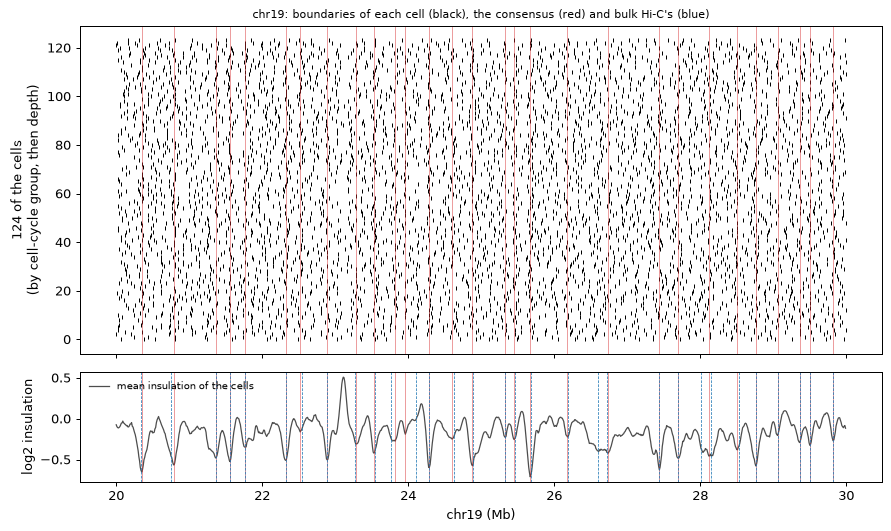

In [7]:
R0, R1 = 20_000_000, 30_000_000
per_cell = cd.results["tads.single_cell.cells"]
view = sc_bounds[(sc_bounds["start"] >= R0) & (sc_bounds["start"] < R1)]
order = cd.cells.loc[top].sort_values(["group", "n_contacts"]).index[::6]   # every 6th cell, for legibility
row = {c: k for k, c in enumerate(order)}
pc = per_cell[(per_cell["start"] >= R0) & (per_cell["start"] < R1) & per_cell["cell_id"].isin(row)]
bulk_b = cd.results["tads.bonev.boundaries"]
bulk_b = bulk_b[(bulk_b["chrom"] == "chr19") & (bulk_b["start"] >= R0) & (bulk_b["start"] < R1)]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.scatter(pc["start"] / 1e6, [row[c] for c in pc["cell_id"]], s=14, c="k", marker="|", lw=0.8)
a1.set_ylabel(f"{len(order)} of the cells\n(by cell-cycle group, then depth)")
a1.set_title("chr19: boundaries of each cell (black), the consensus (red) and bulk Hi-C's (blue)", fontsize=9)
a2.plot(view["start"] / 1e6, view["insulation"], color="0.3", lw=1, label="mean insulation of the cells")
for s in view.loc[view["consensus"], "start"] / 1e6:
    a1.axvline(s, color="C3", lw=0.6, alpha=0.6); a2.axvline(s, color="C3", lw=0.6, alpha=0.6)
for s in bulk_b["start"] / 1e6:
    a2.axvline(s, color="C0", lw=0.6, ls="--")
a2.set_xlabel("chr19 (Mb)"); a2.set_ylabel("log2 insulation"); a2.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 3. Compartment values of every cell: scA/B

`uc.tl.single_cell_compartments` gives each cell and bin the mean CpG frequency of the bin's contact partners
in that cell (Tan et al. 2021, Dip-C), ranked per cell.  Against the compartment eigenvector (E1) of the pooled
map of the same cells:

In [8]:
genome = ds.fetch("mm10_genome", verbose=False)       # UCSC mm10: CpG (scA/B) and GC (E1 phasing) per bin
AUTOSOMES = [f"chr{k}" for k in range(1, 20)]
t = time.time()
scab = uc.tl.single_cell_compartments(cd, cells=top, track=genome, resolution=1_000_000, chrom=AUTOSOMES)
print(f"scA/B: {scab.shape[0]} cells x {scab.shape[1]} bins in {time.time() - t:.0f} s")

rebin_map(cd, "pooled.top742", resolution=1_000_000, key_added="pooled_1mb")
e1 = uc.tl.call_compartments(cd, method="eig", contacts="pooled_1mb", chrom=AUTOSOMES, phasing=genome)
e1.index = e1["chrom"].astype(str) + ":" + e1["start"].astype(str) + "-" + e1["end"].astype(str)
common = scab.columns.intersection(e1.index)
r = scab[common].T.corrwith(e1.loc[common, "E1"])         # each cell's scA/B vs the pooled E1
cellr = cd.cells.loc[r.index].assign(r=r.values)
print(f"mean scA/B vs pooled E1: r = {np.corrcoef(scab[common].mean(), e1.loc[common, 'E1'])[0, 1]:.2f}; "
      f"per cell: median r = {r.median():.2f}")
cellr.groupby("group", observed=True)["r"].agg(["size", "median"]).round(2)

scA/B: 742 cells x 2473 bins in 95 s


mean scA/B vs pooled E1: r = 0.80; per cell: median r = 0.75


,size,median
group,,
G1,128,0.67
early-S,302,0.76
late-S/G2,265,0.75
post-M,4,0.51
pre-M,14,0.69


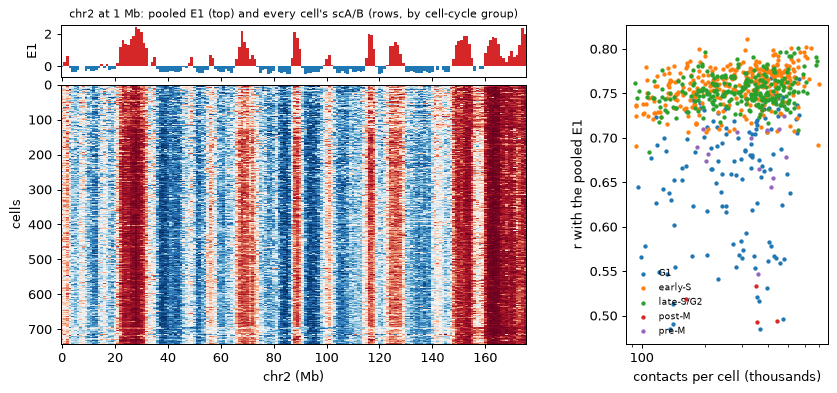

In [9]:
chr_ = "chr2"
cols = [c for c in common if c.startswith(chr_ + ":")]
order = cellr.sort_values(["group", "n_contacts"]).index
fig = plt.figure(figsize=(11, 4.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 5], width_ratios=[3, 1.3], hspace=0.05, wspace=0.3)
axe = fig.add_subplot(gs[0, 0]); axh = fig.add_subplot(gs[1, 0], sharex=axe); axs = fig.add_subplot(gs[:, 1])
x = np.arange(len(cols)); v = e1.loc[cols, "E1"].to_numpy()
axe.bar(x, v, width=1, color=np.where(v > 0, "C3", "C0")); axe.set_ylabel("E1"); axe.tick_params(labelbottom=False)
axe.set_title(f"{chr_} at 1 Mb: pooled E1 (top) and every cell's scA/B (rows, by cell-cycle group)", fontsize=9)
axh.imshow(scab.loc[order, cols].to_numpy(), aspect="auto", cmap="RdBu_r", interpolation="none")
axh.set_xlabel(f"{chr_} (Mb)"); axh.set_ylabel("cells")
for k, (g, sub) in enumerate(cellr.groupby("group", observed=True)):
    axs.scatter(sub["n_contacts"] / 1e3, sub["r"], s=6, label=g, color=f"C{k}")
axs.set_xscale("log"); axs.set_xlabel("contacts per cell (thousands)"); axs.set_ylabel("r with the pooled E1")
axs.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}")); axs.xaxis.set_minor_formatter(plt.NullFormatter())
axs.legend(fontsize=7, frameon=False)
plt.show()

G1 cells follow the pooled E1 less than the cells in S and G2 at the same depth (median r 0.67 against 0.75
in the table above) — the per-cell values carry the cell's state, not only its depth.  Much of scA/B is the CpG
track itself (CpG-rich bins contact CpG-rich bins): the cell-type-specific part
is smaller than the correlation suggests (see [calling structures from single cells](../schic/structures)), and cells
with few contacts are noisy.

## 4. The tracing callers on reconstructed structures

`ds.load("tan2018_gm12878")` holds the authors' Dip-C structures of 14 GM12878 cells (20 kb particles, one
trace per cell, chromosome and homolog) next to their per-cell maps.  The tracing callers take it as they
take imaging; the reference is the E1 of bulk Hi-C (Rao et al. 2014), and the pooled maps of the same cells.

In [10]:
gm = ds.load("tan2018_gm12878", backed=True)
print(gm)
chr21 = gm.get_chrom("chr21")                                  # in memory: 28 homolog traces, 20 kb particles
hg19_chr21 = ds.fetch("hg19_chr21", verbose=False)
add_sequence_features(chr21, ds.fetch("hg19_genome", verbose=False), features=["gc_fraction"])   # GC per locus
                                                               # (every bin of the genome): names A (GC-rich), as E1
t = time.time()
struct = uc.tl.call_compartments(chr21, method="axes_pc", params=CompartmentCallerParams(a_track="seq.gc_fraction"),
                                 key_added=None)               # from the 3-D distances
print(f"compartments from {chr21.n_traces} chr21 structures in {time.time() - t:.0f} s")

gm.link_cool(ds.fetch("rao2014_gm12878_chr21", verbose=False), key="rao")
rebin_map(gm, "rao", resolution=100_000, key_added="rao_100kb")
rao = uc.tl.call_compartments(gm, method="eig", contacts="rao_100kb", chrom="chr21",
                              phasing=hg19_chr21, key_added="compartments.rao")
uc.tl.pseudobulk(gm, trans=False, key_prefix="pooled", out_dir=OUT)            # the same 14 cells' contacts
rebin_map(gm, "pooled.all", resolution=100_000, key_added="pooled_100kb")
pooled_e1 = uc.tl.call_compartments(gm, method="eig", contacts="pooled_100kb", chrom="chr21",
                                    phasing=hg19_chr21, key_added=None)
pd.DataFrame({"structures (axes PC)": compare_compartments(chr21, struct, rao),
              "pooled map (E1)": compare_compartments(chr21, pooled_e1, rao)}).T[["agreement", "pearson_r"]].round(2)

ChromData (backed: tan2018_gm12878.chromdata.zarr): n_spots=3832898, n_traces=639, n_cells=14, n_bins=140938
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['gsm', 'cell_type', 'dataset', 'n_lines', 'n_contacts', 'n_cis', 'n_trans', 'n_dropped', 'n_pixels_5kb', 'frac_cis', 'n_particles', 'n_traces', 'rmsd_rep1', 'median_dev_rep1', 'rmsd_rep2', 'median_dev_rep2'] (14 cells)
  spot_tracks:    ['rep_deviation']
  traces:  ['cell_id', 'chrom', 'homolog', 'n_particles'] (639 traces)
  layers:  ['rep1', 'rep2']
  uns:     ['genome_assembly', 'source', 'haplotypes', 'linked_scool', 'structures', 'xyz_unit', 'dataset']


compartments from 28 chr21 structures in 144 s


,agreement,pearson_r
structures (axes PC),0.86,0.76
pooled map (E1),0.95,0.94


Compartments come out of the structures (and, on 28 homologs, about as well as from imaging with as many
traces); the tracing callers do not find TADs or loops on tens of reconstructions — pool the cells or call
across them (routes 1 and 2) for those.

| Structure | Route that works with tens to hundreds of cells |
|-----------|--------------------------------------------------|
| loops | across cells (SnapHiC), ≥ ~100 cells of a type; pooled maps only at near-bulk depth |
| domain boundaries | across cells (consensus of single-cell boundaries) or a pooled map |
| compartments | per cell (scA/B), pooled maps, or reconstructed structures |

In [11]:
print(f"total run time {(time.time() - T0) / 60:.1f} min")

total run time 11.4 min
